# 01 - SMA crossover demo

**SYNTHETIC DATA - not market data.** Results show software behaviour, not an investment edge.

This notebook is deliberately thin: all logic lives in the `backtester` package. It runs SMA 50/200 (a-priori parameters) on the development sample *before* the protected hold-out, with the detailed cost model and next-open execution.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from backtester import experiments as ex
from backtester.config import make_run_factory
from backtester.performance import compute_metrics, metrics_frame
from backtester.strategies import build_strategy

ctx = ex.Context(Path.cwd())   # finds the project folder from notebooks/
ex.ensure_datasets(ctx.root)
print('project:', ctx.root.name, '| hold-out starts', ctx.holdout_start.date(), '(never used here)')

project: backtester | hold-out starts 2022-01-01 (never used here)


In [2]:
cfg = ctx.config('sma')
full, research, universe, mode = ctx.load(cfg)
print(research)
run = make_run_factory(cfg, universe, mode)
res = run(research, build_strategy('sma_crossover', **cfg['strategy']['params']), None)
bench = run(research, build_strategy(cfg['benchmark']['name'], **cfg['benchmark']['params']), None)
first = res.equity.index[res.equity['gross_exposure'] > 0][0]
r, b = res.returns(first), bench.returns(first)
m = compute_metrics(r, benchmark=b, equity_frame=res.equity, round_trips=res.round_trips)
metrics_frame({'sma_50_200': m}).T.head(40)

MarketData(6 symbols, 4435 sessions, 2005-01-03..2021-12-31)


,sma_50_200
n_periods,4235
start,2005-10-10
end,2021-12-31
total_return,0.720692
cagr,0.032822
mean_daily_arith,0.000215
mean_ann_arith,0.054108
ann_vol,0.208859
sharpe,0.259063
sharpe_per_period,0.016319


## Order / fill / accounting audit (first orders)

Decision price = close at signal; reference price = next open; shortfall = spread + slippage + impact (embedded in the fill price, charged once).

In [3]:
res.reconciliation().head(8)

,timestamp,order_id,symbol,quantity,decision_price,reference_price,fill_price,reference_value,execution_value,execution_shortfall,spread_cost,slippage_cost,impact_cost,commission,delay_cost_vs_decision,components_minus_shortfall
0,2005-10-10,1,ETF000,3824.0,66.040216,66.135675,66.188532,252902.821200,253104.945774,202.124574,50.580564,25.290282,126.253727,25.310495,365.035216,-3.240075e-12
1,2005-10-10,2,ETF001,5004.0,50.470308,49.991509,50.017994,250157.511036,250290.044398,132.533362,50.031502,25.015751,57.486108,25.029004,-2395.910196,-3.495870e-12
2,2005-10-10,3,ETF004,4878.0,51.772209,51.935295,51.980545,253340.369010,253561.096449,220.727439,50.668074,25.334037,144.725329,25.356110,795.533508,-1.742251e-11
3,2005-10-10,4,ETF005,1409.0,179.189573,178.246254,178.345238,251148.971886,251288.439850,139.467964,50.229794,25.114897,64.123272,25.128844,-1329.136471,2.771117e-11
4,2005-11-11,5,ETF000,-3824.0,58.011298,58.029143,57.982578,-221903.442832,-221725.377102,178.065730,44.380689,22.190344,111.494697,22.172538,-68.239280,-1.267608e-11
5,2005-11-11,6,ETF001,1300.0,51.463535,51.831377,51.852839,67380.790100,67408.690922,27.900822,13.476158,6.738079,7.686585,6.740869,478.194600,-2.312817e-12
6,2005-11-11,7,ETF004,1972.0,47.362391,47.374513,47.400644,93422.539636,93474.069135,51.529499,18.684508,9.342254,23.502738,9.347407,23.904584,-4.746425e-12
7,2005-11-11,8,ETF005,344.0,185.017056,184.910235,184.981759,63609.120840,63633.725255,24.604415,12.721824,6.360912,5.521679,6.363373,-36.746424,6.611600e-12


In [4]:
res.cost_summary()

{'commissions': 9709.42540289221,
 'spread_costs': 19418.537738417996,
 'slippage_costs': 9709.268869208998,
 'impact_costs': 43347.564280377184,
 'interest': 63339.67716385916,
 'borrow_fees': 0.0,
 'traded_notional': 97094254.02892219,
 'total_trading_costs': 82184.7962908964,
 'net_financing': 63339.67716385916}

## Saved tearsheet (written by `scripts/run_sma.py`)

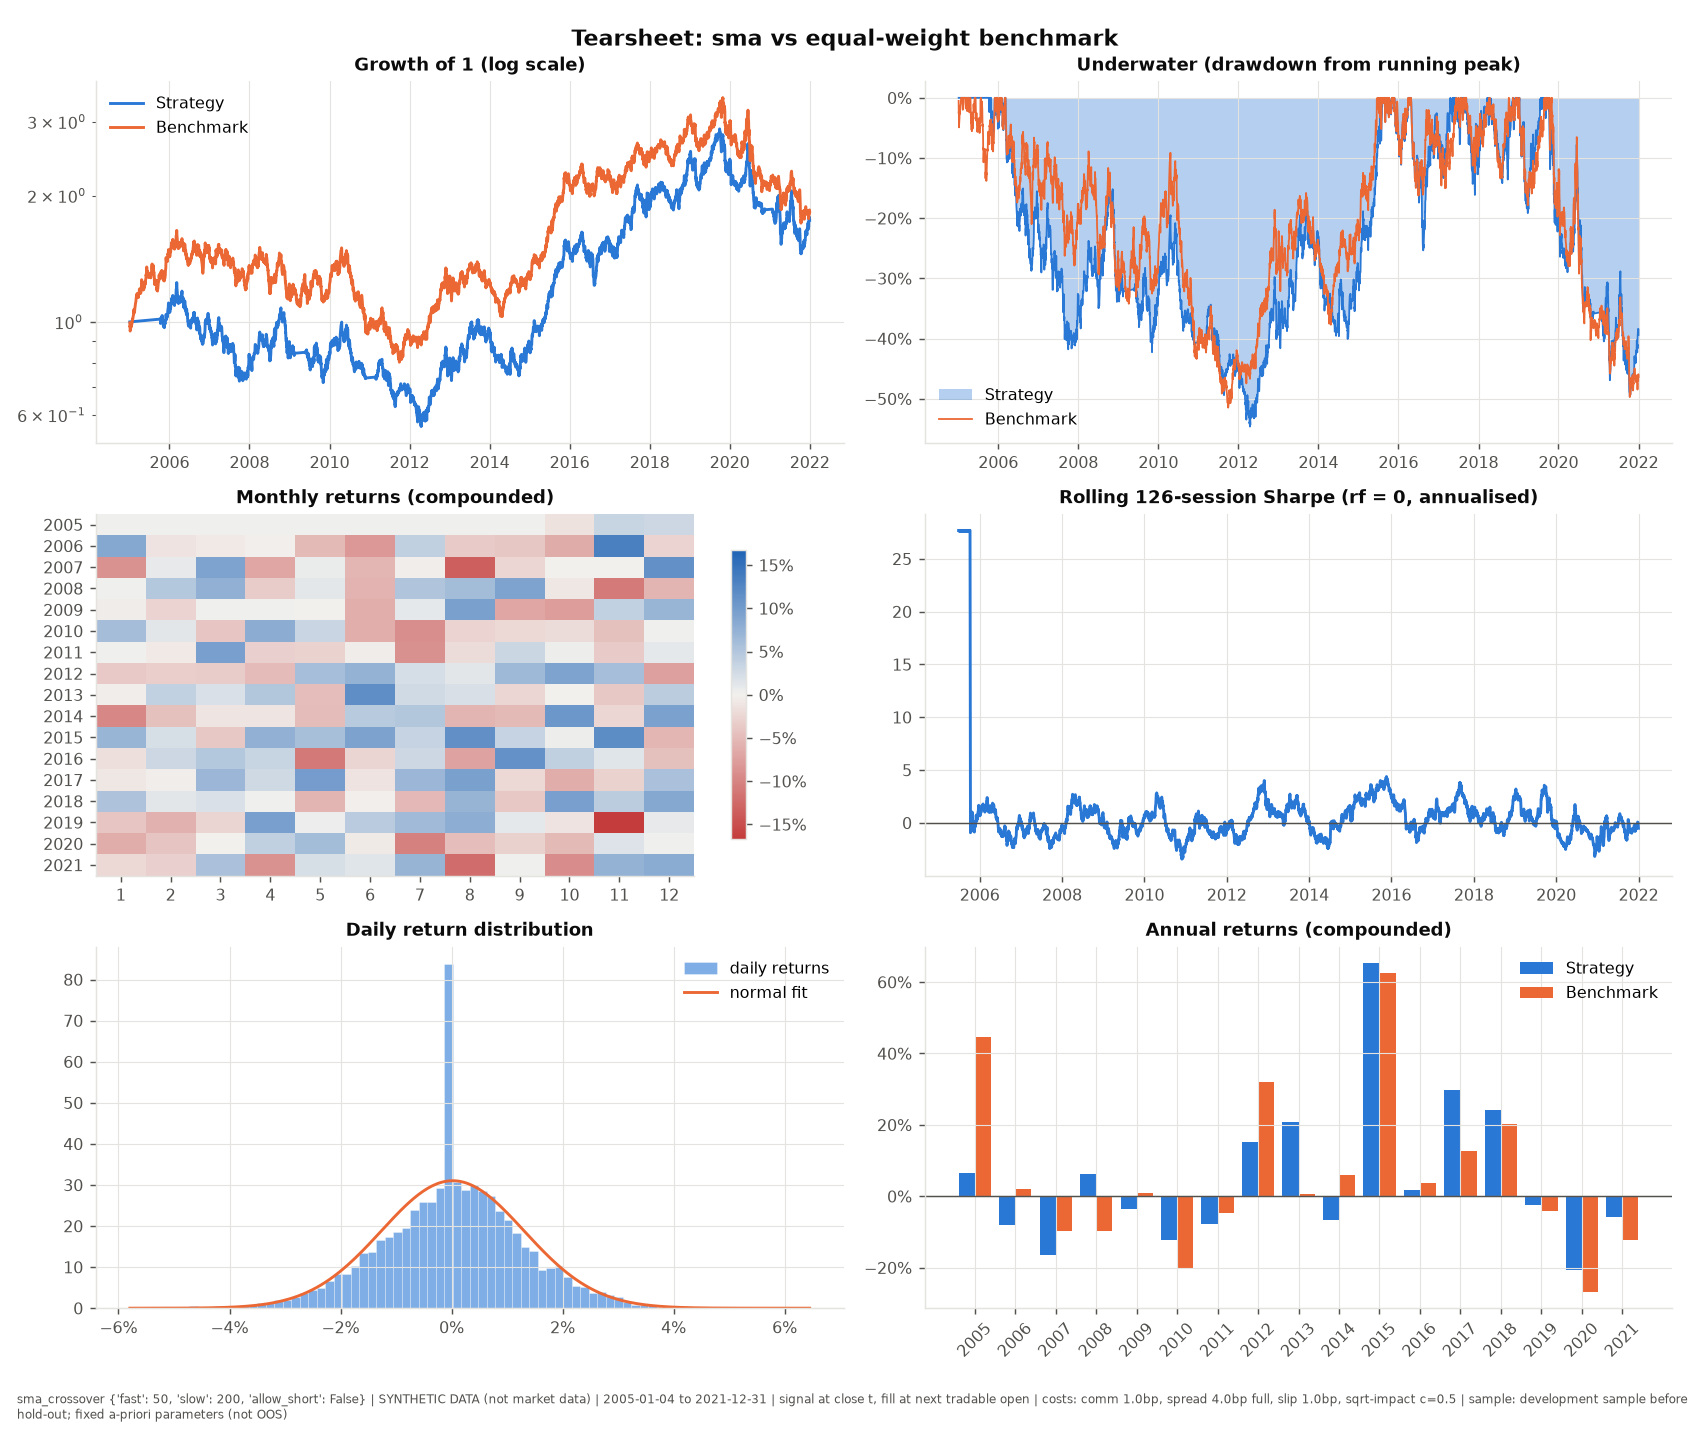

In [5]:
display(Image(filename=str(ctx.figs / '03_sma_tearsheet.png'), width=900))